# Wolfire et al. (1995) の検証計算

`test/test.out` が出力した平衡状態から、水素密度に対する圧力・電離分率・冷却率と加熱率、および温度に対する平均分子量を描きます。柱密度、金属量、ISRF、炭素・酸素存在量をそれぞれ変えた結果を比較します。

再計算するには README の手順で `test/out/wolfire` に結果を出力し、下のセルを上から実行します。保存済みの結果を使う場合は、最初のセルの `run_dir` に実行ディレクトリを指定してください。出力ファイルは `out/`、`results/`、実行ディレクトリ直下の順に探します。既定の実行ディレクトリに結果がない場合は [同梱の参照データ](../test/wolfire1995/reference/) を描画します。計算条件の詳細は [Wolfire (1995) の検証手順](../test/README.md#wolfire-et-al-1995-の検証計算と描画) にあります。

In [1]:
%matplotlib inline

import sys
from pathlib import Path

from IPython.display import Markdown, display
import matplotlib.pyplot as plt

cwd = Path.cwd()
repo_root = next(
    (directory for directory in (cwd, *cwd.parents)
     if (directory / "plot" / "PlotWolfire1995.ipynb").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("EQCLib のリポジトリ内からノートブックを実行してください。")

run_dir = repo_root / "test" / "out" / "wolfire"

plot_dir = str(repo_root / "plot")
if plot_dir not in sys.path:
    sys.path.insert(0, plot_dir)

from plot_style import PLOT_STYLE
from plot_wolfire1995 import (
    WolfireResults, plot_hi_fraction, plot_hii_fraction, plot_mean_molecular_weight,
    REFERENCE, plot_pressure, plot_thermal_rates, plot_x0_scaling,
)

try:
    results = WolfireResults(run_dir)
except FileNotFoundError as error:
    raise FileNotFoundError(
        f"{run_dir} に計算結果がありません。run_dir を確認するか、README の手順で計算してください。"
    ) from error

data_dir = results.data_dir
display_dir = data_dir.relative_to(repo_root) if repo_root in data_dir.parents else data_dir.name
print(f"計算結果 {display_dir}")
rejected = results.rejected()
if rejected is not None:
    print(f"求解に失敗した点 {len(rejected)} 件")
    if rejected:
        table = ["| 出力ファイル | 点の番号 | n_H [cm⁻³] | T [K] | status |", "|---|---:|---:|---:|---:|"]
        for dataset, sample, density, temperature, status in rejected:
            temperature_text = f"{temperature:,.0f}" if temperature is not None else "—"
            table.append(f"| `{dataset}` | {sample} | {density:.4g} | {temperature_text} | {status} |")
        display(Markdown("\n".join(table)))

計算結果 test/wolfire1995/reference
求解に失敗した点 0 件


## 平衡圧力と水素密度

圧力に対応する量として水素核数密度と温度の積 $n_{\rm H}T$ を表示します。太い黒線が基準条件（$N_{\rm tot}=10^{19}$ cm$^{-2}$、ISRF = 1、$Z=Z_\odot$）です。

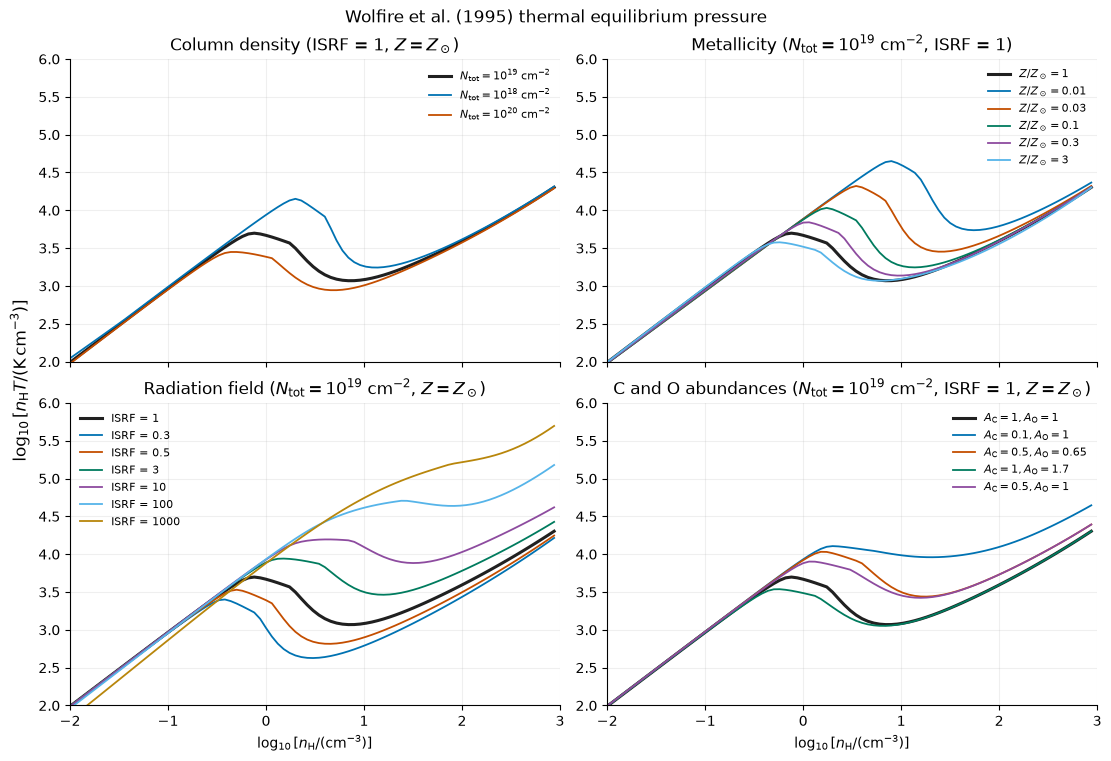

In [2]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_pressure(results)
    display(fig)
    plt.close(fig)

## 放射場スケーリング $X_0$ による規格化

この比較では、試験コードが $X_0$ と ISRF を同じ倍率で変えています。横軸は $n_{\rm H}/X_0$、縦軸は $n_{\rm H}T/X_0$ です。

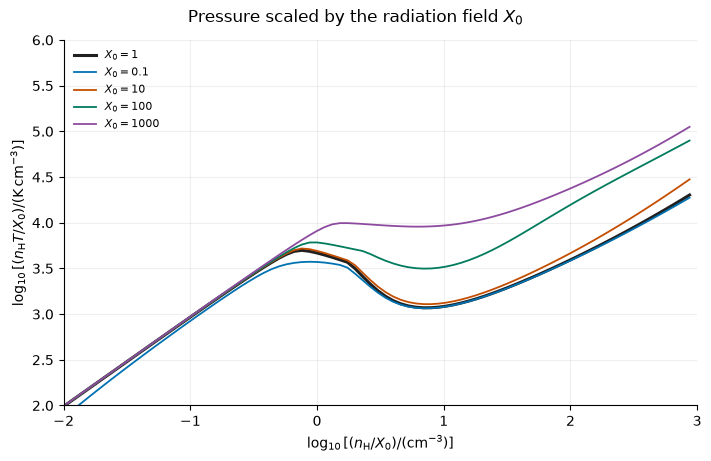

In [3]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_x0_scaling(results)
    display(fig)
    plt.close(fig)

## 水素の電離分率と中性分率

H II の分率 $n_{\rm HII}/n_{\rm H}$ を対数、H I の分率 $n_{\rm HI}/n_{\rm H}$ を線形目盛で表示します。電子分率 $x_e=n_e/n_{\rm H}$ は次節に示します。

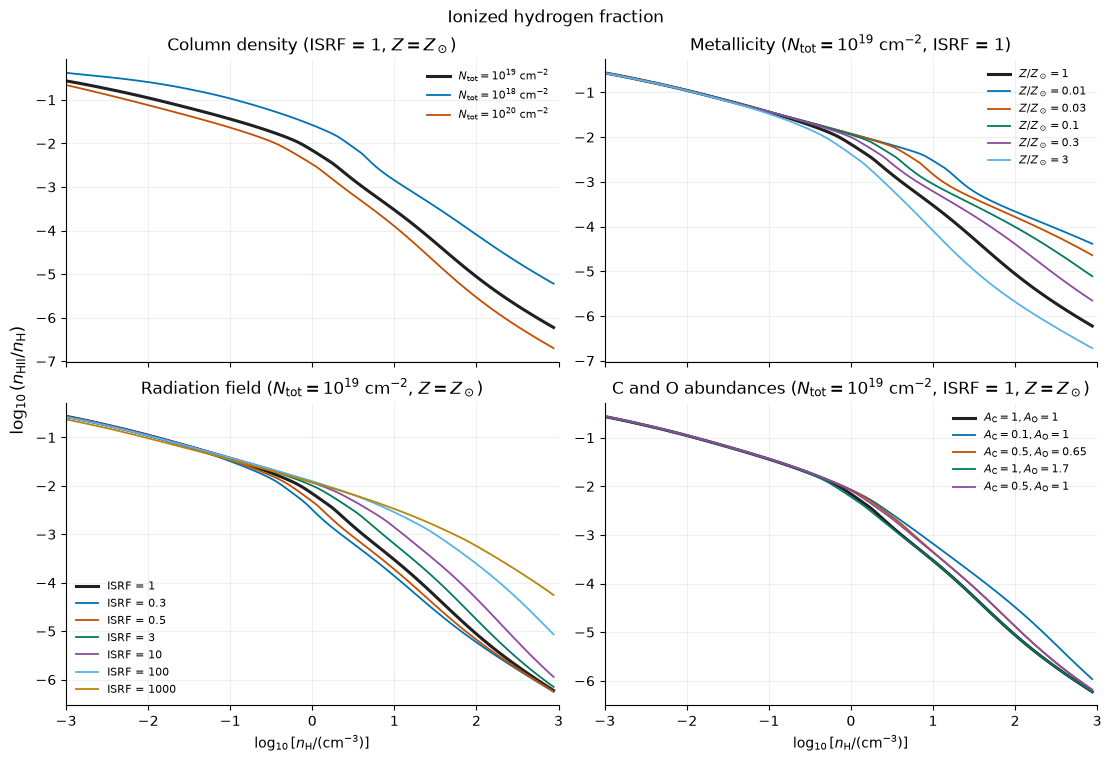

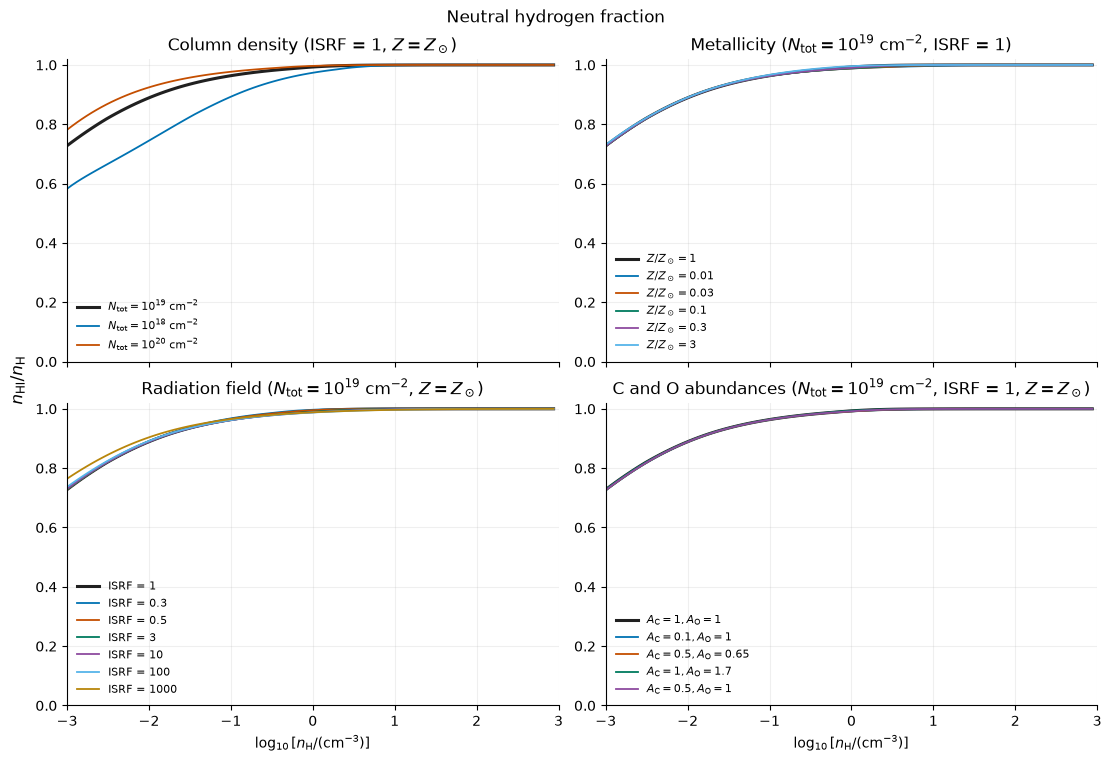

In [4]:
with plt.rc_context(PLOT_STYLE):
    for plot in (plot_hii_fraction, plot_hi_fraction):
        fig = plot(results)
        display(fig)
        plt.close(fig)

## 平均分子量と電子分率

$y_{\rm He}=n_{\rm He}/n_{\rm H}=0.1$ の原子・イオンガスとして、平均分子量を $\mu=(1+4y_{\rm He})/(1+y_{\rm He}+x_e)$ で求めます。$x_e$ は出力された電子数密度から計算します。水平線は中性、H のみ電離、完全電離の各極限です。

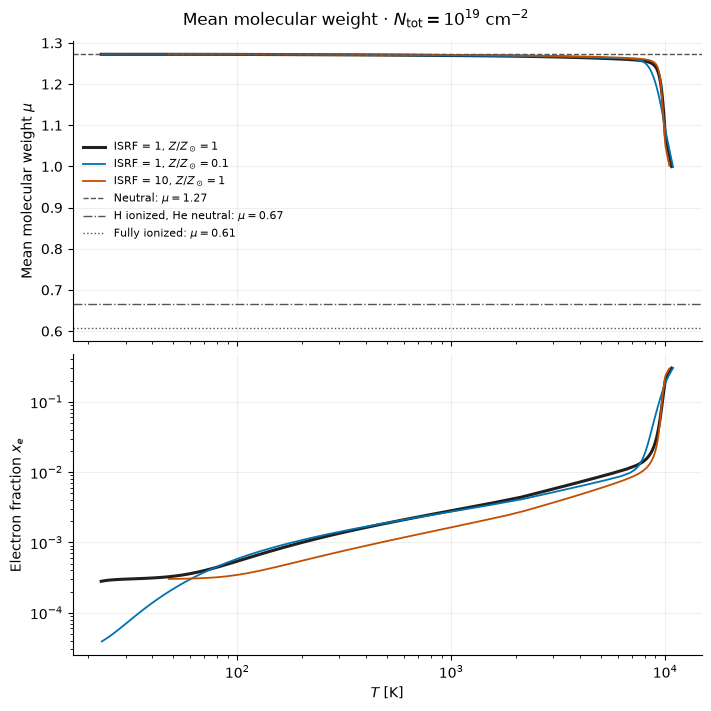

In [5]:
with plt.rc_context(PLOT_STYLE):
    fig = plot_mean_molecular_weight(results)
    display(fig)
    plt.close(fig)

## 冷却率・加熱率と水素密度

水素核数密度 $n_{\rm H}$ に対して、体積あたりの冷却率・加熱率（erg s⁻¹ cm⁻³）を成分別に対数目盛で表示します。太い黒線はそれぞれの合計です。正の値がある成分を描画し、縦軸の下限は各成分のピークが見える範囲に調整します。

既定では基準条件（$N_{\rm tot}=10^{19}$ cm⁻²、ISRF = 1、$Z=Z_\odot$）を表示します。別の条件を描くには、`rate_case` を対応する `PostProcessMap*.dat` のファイル名に変更してください。旧形式の保存データでは、記録済みの成分を表示します。追加成分を取得するにはテストを再ビルドして実行してください。

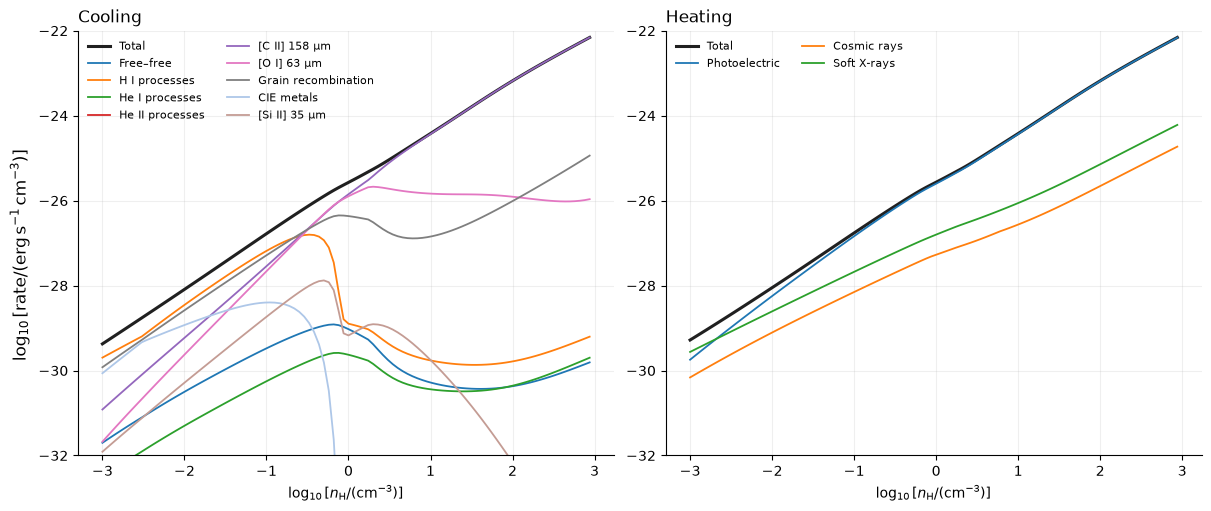

In [6]:
rate_case = REFERENCE
# 軸範囲は log10 単位で (下限, 上限) を指定します。None は自動設定です。
xlim = None             # 例 (-2, 3)
#cooling_ylim = None     # 例 (-36, -22)
#heating_ylim = None     # 例 (-31, -22)
cooling_ylim = (-32, -22)
heating_ylim = cooling_ylim
with plt.rc_context(PLOT_STYLE):
    fig = plot_thermal_rates(
        results, rate_case, xlim=xlim, cooling_ylim=cooling_ylim, heating_ylim=heating_ylim,
    )
    display(fig)
    plt.close(fig)